# Predicting the Falcon 9 landing class

Four classifier families are tuned in a preprocessing pipeline. Stratified 80/20 splitting gives 72 training and 18 test launches. Five-fold training CV selects the winner before test evaluation. Imputation, scaling and encoding fit only on each training fold. Outcome-derived and potentially future core-reuse fields are excluded.

An independent chronological split and time-series CV assess temporal generalization. Accuracy, balanced accuracy, precision, recall, F1, confusion matrix and majority baselines are reported. The held-out sample is small.

In [1]:
%matplotlib inline
"""Reproducible SpaceX capstone: scraping, SQL, visual EDA and model evaluation."""
from pathlib import Path
from io import StringIO
import calendar
import json
import re
import sqlite3
import warnings

import numpy as np
import pandas as pd
import matplotlib

import matplotlib.pyplot as plt
import seaborn as sns
from bs4 import BeautifulSoup
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold, TimeSeriesSplit, train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, precision_score, recall_score, confusion_matrix


ROOT = Path.cwd().parent
DATA = ROOT / 'data'
FIG = ROOT / 'figures'


In [2]:
def model_analysis(df):
    numeric = ["FlightNumber", "PayloadMass", "Flights", "Block"]
    categorical = ["Orbit", "LaunchSite", "GridFins", "Reused", "Legs"]
    X = df[numeric + categorical].copy()
    # Reverse the frozen dataset's exact mean-imputation sentinel, then impute per fold.
    X["PayloadMass"] = X.PayloadMass.mask(np.isclose(X.PayloadMass, 6104.959411764705, rtol=1e-10))
    # Categorical values have consistent string types for sklearn's encoder.
    X[categorical] = X[categorical].astype(str)
    y = df.Class
    preprocess = ColumnTransformer([
        ("numeric", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), numeric),
        ("categorical", Pipeline([("impute", SimpleImputer(strategy="most_frequent")), ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), categorical),
    ])
    models = {
        "Logistic regression": (LogisticRegression(max_iter=10000), {"model__C": [0.01, 0.1, 1, 10]}),
        "Support vector machine": (SVC(), {"model__kernel": ["linear", "rbf"], "model__C": [0.1, 1, 10], "model__gamma": ["scale", 0.1]}),
        "Decision tree": (DecisionTreeClassifier(random_state=42), {"model__max_depth": [2, 3, 4, 5, None], "model__min_samples_leaf": [1, 2, 4]}),
        "K nearest neighbors": (KNeighborsClassifier(), {"model__n_neighbors": [3, 5, 7, 9], "model__p": [1, 2], "model__weights": ["uniform", "distance"]}),
    }
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    records, fitted = [], {}
    for name, (model, params) in models.items():
        pipeline = Pipeline([("prepare", preprocess), ("model", model)])
        search = GridSearchCV(pipeline, params, scoring="accuracy", cv=cv, n_jobs=1)
        search.fit(X_train, y_train)
        predicted = search.predict(X_test)
        records.append({"Model": name, "CV_accuracy": search.best_score_, "CV_std": search.cv_results_["std_test_score"][search.best_index_],
                        "Test_accuracy": accuracy_score(y_test, predicted), "Test_balanced_accuracy": balanced_accuracy_score(y_test, predicted),
                        "Test_precision": precision_score(y_test, predicted, zero_division=0), "Test_recall": recall_score(y_test, predicted, zero_division=0),
                        "Test_F1": f1_score(y_test, predicted, zero_division=0), "Parameters": search.best_params_,
                        "Confusion_matrix": confusion_matrix(y_test, predicted, labels=[0, 1]).tolist()})
        fitted[name] = search
    # Select by training CV, not by inspecting the test accuracy.
    winner = max(records, key=lambda r: r["CV_accuracy"])
    comparison = pd.DataFrame([{k: v for k, v in r.items() if k not in ["Parameters", "Confusion_matrix"]} for r in records])
    comparison.to_csv(DATA / "model_comparison.csv", index=False)
    fig, ax = plt.subplots(figsize=(13, 6))
    shown = comparison.melt(id_vars="Model", value_vars=["CV_accuracy", "Test_accuracy"], var_name="Evaluation", value_name="Accuracy")
    sns.barplot(data=shown, x="Model", y="Accuracy", hue="Evaluation", palette=["#64748b", "#2563eb"], ax=ax)
    ax.set(title="Four classifiers: training cross-validation and held-out test", ylabel="Accuracy", xlabel="", ylim=(0, 1.05))
    ax.tick_params(axis="x", labelsize=12)
    fig.tight_layout()
    fig.savefig(FIG / "07_model_comparison.png", dpi=170)
    plt.close(fig)
    fig, ax = plt.subplots(figsize=(8, 6))
    sns.heatmap(winner["Confusion_matrix"], annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=["Predicted 0", "Predicted 1"], yticklabels=["Actual 0", "Actual 1"], ax=ax)
    ax.set_title(f"Best CV model: {winner['Model']}")
    fig.tight_layout()
    fig.savefig(FIG / "08_confusion_matrix.png", dpi=170)
    plt.close(fig)
    # An independent temporal evaluation highlights the shift toward later successful landings.
    split = int(len(X) * 0.8)
    temporal_records = []
    temporal_cv = TimeSeriesSplit(n_splits=3)
    for name, (model, params) in models.items():
        search = GridSearchCV(Pipeline([("prepare", preprocess), ("model", model)]), params, scoring="accuracy", cv=temporal_cv, n_jobs=1)
        search.fit(X.iloc[:split], y.iloc[:split])
        temporal_records.append({"Model": name, "CV_accuracy": search.best_score_, "Test_accuracy": accuracy_score(y.iloc[split:], search.predict(X.iloc[split:]))})
    temporal_best = max(temporal_records, key=lambda r: r["CV_accuracy"])
    return {"records": records, "winner": winner, "train_n": len(X_train), "test_n": len(X_test),
            "test_successes": int(y_test.sum()), "random_majority_baseline": float(y_test.mean()),
            "features": numeric + categorical, "temporal": temporal_records, "temporal_winner": temporal_best,
            "temporal_test_successes": int(y.iloc[split:].sum()), "temporal_baseline": float(y.iloc[split:].mean()),
            "temporal_test_start": df.Date.iloc[split].strftime("%Y-%m-%d")}

,Model,CV_accuracy,CV_std,Test_accuracy,Test_balanced_accuracy,Test_precision,Test_recall,Test_F1
0,Logistic regression,0.848571,0.063489,0.777778,0.666667,0.750000,1.000000,0.857143
1,Support vector machine,0.888571,0.069046,0.777778,0.666667,0.750000,1.000000,0.857143
2,Decision tree,0.860000,0.046812,0.833333,0.791667,0.846154,0.916667,0.880000
3,K nearest neighbors,0.860952,0.095779,0.777778,0.708333,0.785714,0.916667,0.846154


Selected by CV: {
  "Model": "Support vector machine",
  "CV_accuracy": 0.8885714285714286,
  "CV_std": 0.06904597699196899,
  "Test_accuracy": 0.7777777777777778,
  "Test_balanced_accuracy": 0.6666666666666666,
  "Test_precision": 0.75,
  "Test_recall": 1.0,
  "Test_F1": 0.8571428571428571,
  "Parameters": {
    "model__C": 1,
    "model__gamma": "scale",
    "model__kernel": "rbf"
  },
  "Confusion_matrix": [
    [
      2,
      4
    ],
    [
      0,
      12
    ]
  ]
}
Temporal evaluation: [
  {
    "Model": "Logistic regression",
    "CV_accuracy": 0.6666666666666666,
    "Test_accuracy": 0.8333333333333334
  },
  {
    "Model": "Support vector machine",
    "CV_accuracy": 0.7222222222222223,
    "Test_accuracy": 0.8888888888888888
  },
  {
    "Model": "Decision tree",
    "CV_accuracy": 0.7777777777777777,
    "Test_accuracy": 0.8888888888888888
  },
  {
    "Model": "K nearest neighbors",
    "CV_accuracy": 0.6851851851851851,
    "Test_accuracy": 0.8888888888888888
  }
]
Ra

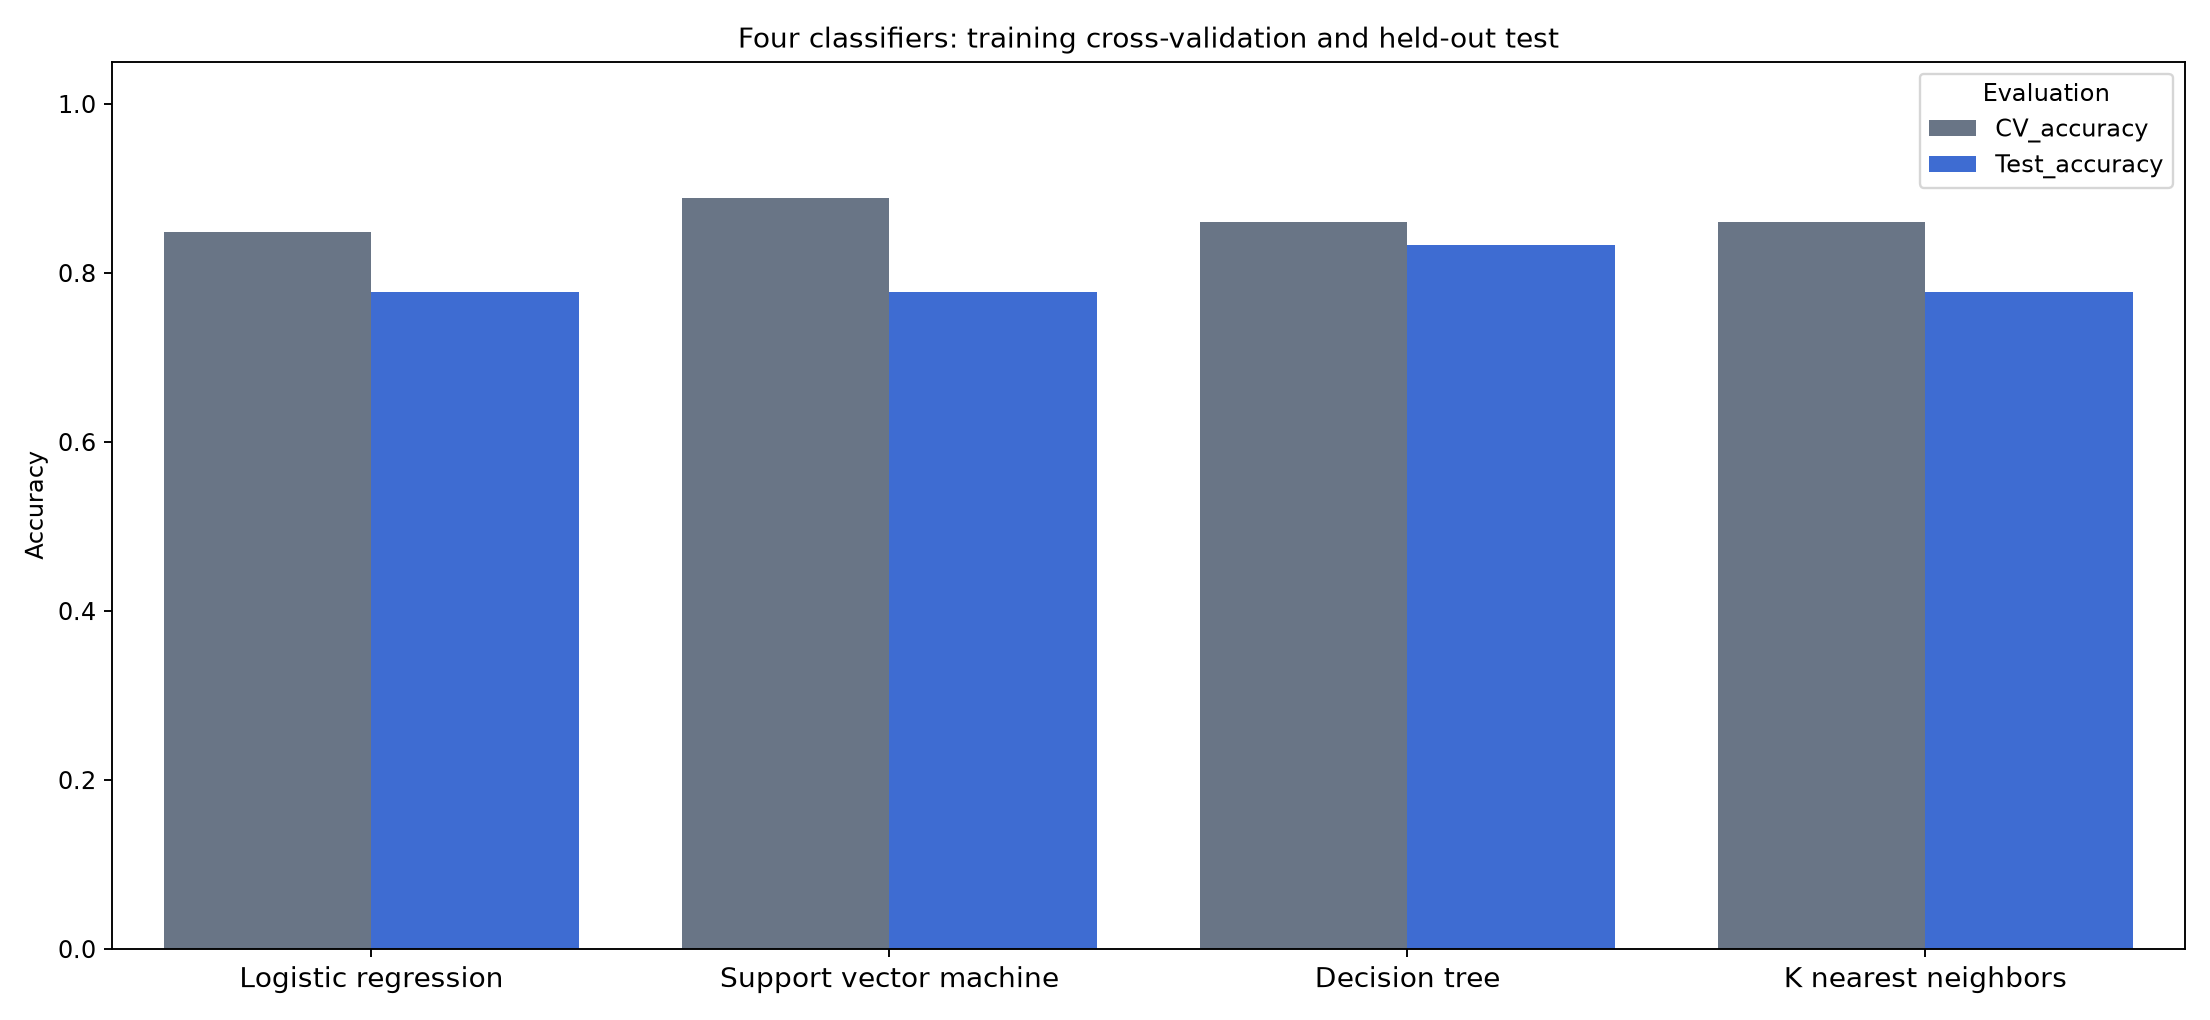

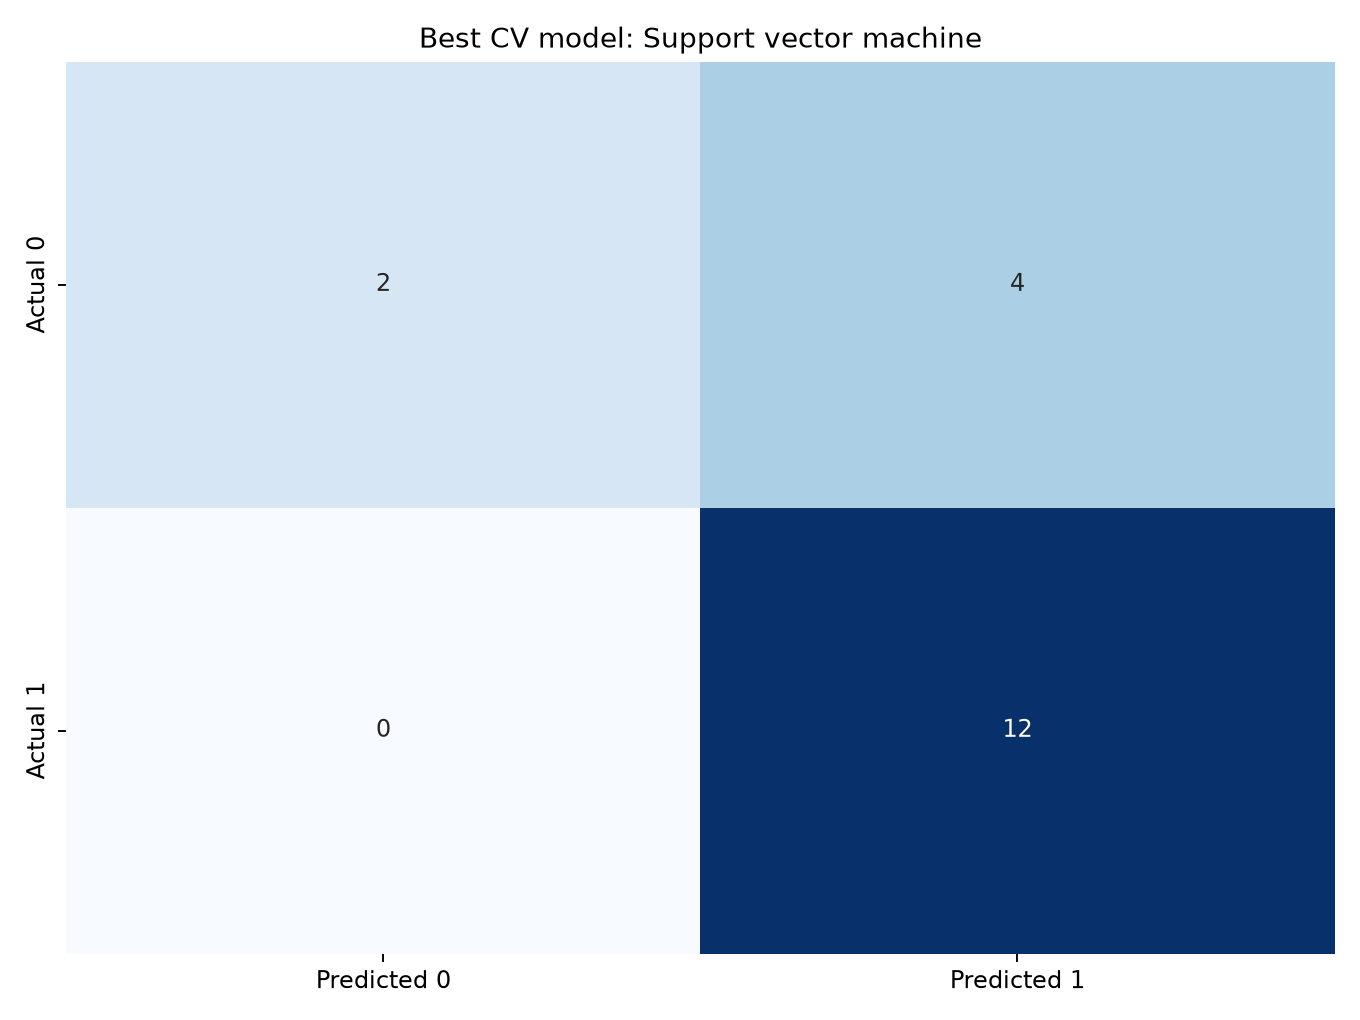

In [3]:
df = pd.read_csv(DATA/'dataset_part_2.csv',parse_dates=['Date'])
models = model_analysis(df)
display(pd.DataFrame([{k:v for k,v in r.items() if k not in ['Parameters','Confusion_matrix']} for r in models['records']]))
print('Selected by CV:',json.dumps(models['winner'],indent=2))
print('Temporal evaluation:',json.dumps(models['temporal'],indent=2))
print('Random baseline:',models['random_majority_baseline'],'Temporal baseline:',models['temporal_baseline'])
from IPython.display import Image
display(Image(filename=str(FIG/'07_model_comparison.png')))
display(Image(filename=str(FIG/'08_confusion_matrix.png')))